# 03 - K-Means vs DBSCAN

Head-to-head comparison on the same data, the **same scaler**, and the same evaluation rules.

Parameters come from the previous notebooks: K-Means with K = 3 (notebook 01), DBSCAN with `eps = 0.2`, `min_samples = 20` (notebook 02).

## 1. Setup, data and features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
SEED = 42
K_FINAL = 3                      # chosen in 01_kmeans.ipynb
EPS, MIN_SAMPLES = 0.2, 20       # chosen in 02_dbscan.ipynb

df = pd.read_csv("../data/customer_segmentation.csv")
df["Income"] = df["Income"].fillna(df["Income"].median())
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]
purchase_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df["total_spent"] = df[mnt_cols].sum(axis=1)
df["purchase_count"] = df[purchase_cols].sum(axis=1)

FEATURES = ["total_spent", "purchase_count"]
X = StandardScaler().fit_transform(df[FEATURES])   # the SAME scaled data goes to both models

## 2. Fit both models

In [2]:
km_labels = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit_predict(X)
db_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X)

df["kmeans_cluster"] = km_labels
df["dbscan_cluster"] = db_labels

## 3. Metrics

DBSCAN excludes noise points from its silhouette, so its score is not directly comparable to K-Means (which scores every customer). For a fair comparison the table also shows K-Means silhouette on **exactly the same non-noise points**.

In [3]:
non_noise = db_labels != -1
db_clusters = len(set(db_labels[non_noise]))

summary = pd.DataFrame([
    {
        "Model": f"K-Means (K={K_FINAL})",
        "Clusters": K_FINAL,
        "Noise %": 0.0,
        "Largest cluster %": round(np.bincount(km_labels).max() / len(df) * 100, 1),
        "Silhouette (all points)": round(silhouette_score(X, km_labels), 4),
        "Silhouette (non-noise points)": round(silhouette_score(X[non_noise], km_labels[non_noise]), 4),
    },
    {
        "Model": f"DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})",
        "Clusters": db_clusters,
        "Noise %": round((~non_noise).mean() * 100, 1),
        "Largest cluster %": round(np.bincount(db_labels[non_noise]).max() / len(df) * 100, 1),
        "Silhouette (all points)": np.nan,   # not defined: noise points have no cluster
        "Silhouette (non-noise points)": round(silhouette_score(X[non_noise], db_labels[non_noise]), 4),
    },
]).set_index("Model")
summary

,Clusters,Noise %,Largest cluster %,Silhouette (all points),Silhouette (non-noise points)
Model,,,,,
K-Means (K=3),3,0.0,45.0,0.5327,0.5526
"DBSCAN (eps=0.2, min_samples=20)",3,5.8,73.2,NaN,0.3448


In [4]:
ari = adjusted_rand_score(km_labels[non_noise], db_labels[non_noise])
print(f"Agreement between the two clusterings (Adjusted Rand Index, non-noise points): {ari:.3f}")
print("(1.0 = identical groupings, ~0 = no better than random)")

Agreement between the two clusterings (Adjusted Rand Index, non-noise points): 0.286
(1.0 = identical groupings, ~0 = no better than random)


## 4. Side-by-side visualization

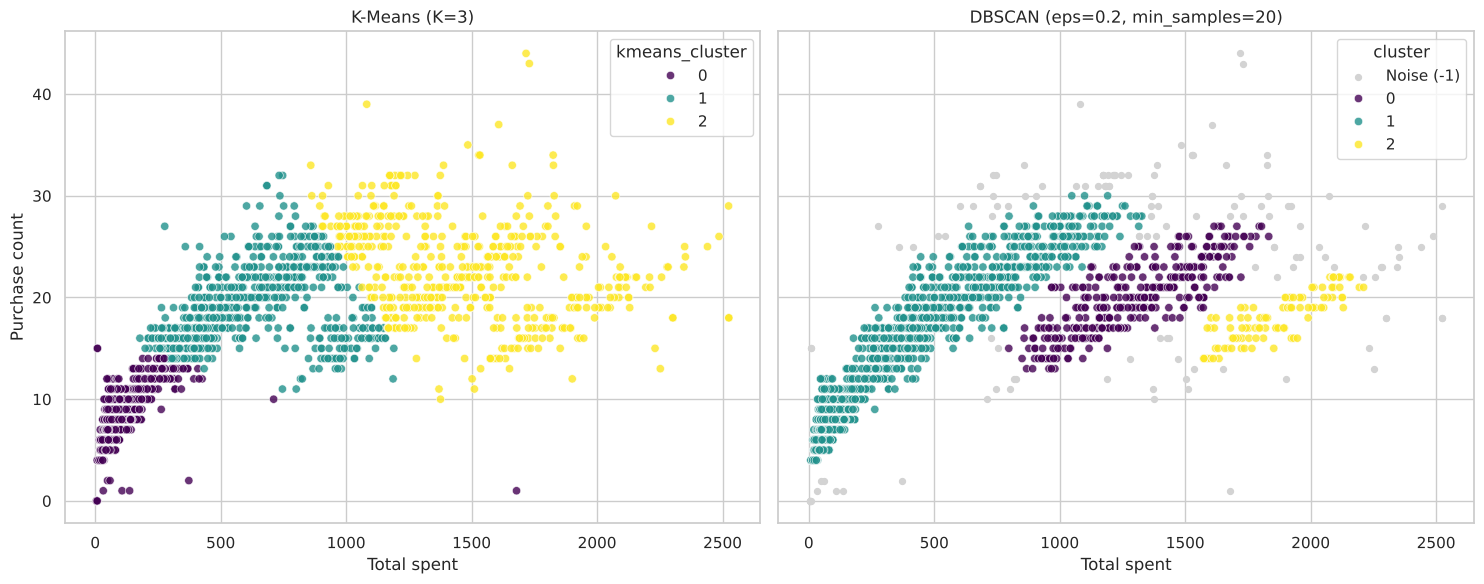

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.scatterplot(ax=axes[0], data=df, x="total_spent", y="purchase_count",
                hue="kmeans_cluster", palette="viridis", alpha=0.8)
axes[0].set_title(f"K-Means (K={K_FINAL})")

noise = df[df["dbscan_cluster"] == -1]
axes[1].scatter(noise["total_spent"], noise["purchase_count"], c="lightgray", s=18, label="Noise (-1)")
sns.scatterplot(ax=axes[1], data=df[df["dbscan_cluster"] != -1], x="total_spent", y="purchase_count",
                hue="dbscan_cluster", palette="viridis", alpha=0.8)
axes[1].set_title(f"DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})")
axes[1].legend(title="cluster")

for ax in axes:
    ax.set_xlabel("Total spent")
    ax.set_ylabel("Purchase count")
plt.tight_layout()
plt.savefig("../images/comparison_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Cluster sizes

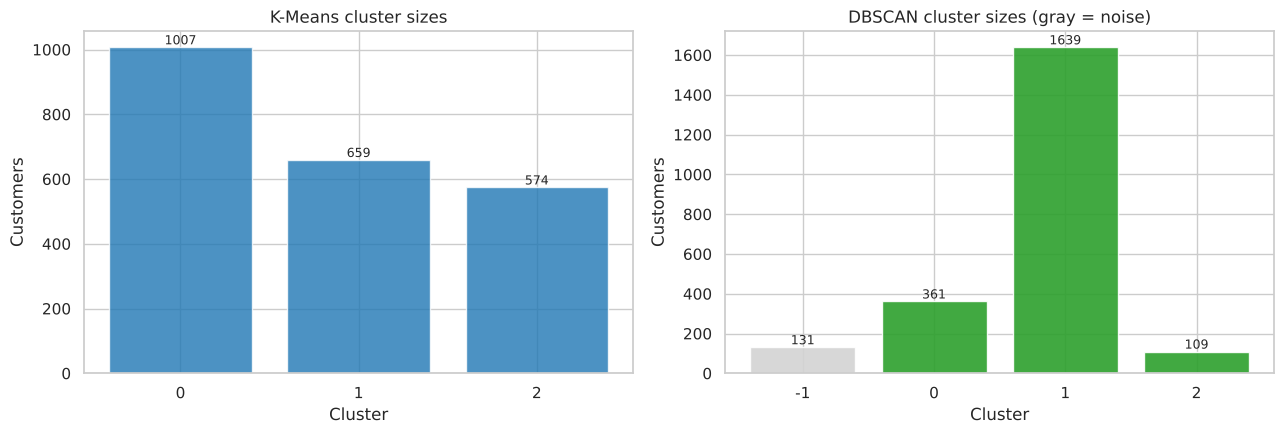

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

km_counts = df["kmeans_cluster"].value_counts().sort_index()
axes[0].bar(km_counts.index.astype(str), km_counts.values, color="tab:blue", alpha=0.8)
axes[0].set(title="K-Means cluster sizes", xlabel="Cluster", ylabel="Customers")

db_counts = df["dbscan_cluster"].value_counts().sort_index()
colors = ["lightgray" if c == -1 else "tab:green" for c in db_counts.index]
axes[1].bar(db_counts.index.astype(str), db_counts.values, color=colors, alpha=0.9)
axes[1].set(title="DBSCAN cluster sizes (gray = noise)", xlabel="Cluster", ylabel="Customers")

for ax in axes:
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("../images/comparison_cluster_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Cluster profiles

In [7]:
cols = ["total_spent", "purchase_count", "Income", "Recency"]

print("K-Means profile (mean values):")
display(df.groupby("kmeans_cluster")[cols].mean().round(2).assign(customers=df["kmeans_cluster"].value_counts().sort_index()))

print("DBSCAN profile (mean values, noise = -1):")
display(df.groupby("dbscan_cluster")[cols].mean().round(2).assign(customers=df["dbscan_cluster"].value_counts().sort_index()))

print("Overall means for reference:")
display(df[cols].mean().round(2).to_frame("overall mean").T)

K-Means profile (mean values):


,total_spent,purchase_count,Income,Recency,customers
kmeans_cluster,,,,,
0,91.32,7.55,35739.01,49.10,1007
1,640.57,19.22,58168.29,48.89,659
2,1468.45,22.69,74374.53,49.37,574


DBSCAN profile (mean values, noise = -1):


,total_spent,purchase_count,Income,Recency,customers
dbscan_cluster,,,,,
-1,1333.63,23.51,72352.89,46.56,131
0,1294.19,20.02,72585.59,52.45,361
1,312.30,12.82,44271.32,48.69,1639
2,1864.38,18.07,80465.55,47.45,109


Overall means for reference:


,total_spent,purchase_count,Income,Recency
overall mean,605.8,14.86,52237.98,49.11


## 7. Conclusions

- **K-Means** assigns every customer and produces three segments (45 % / 29 % / 26 % of customers). On the same non-noise points its silhouette (0.55) is clearly higher than DBSCAN's (0.34). It is the better fit for the actual goal here: splitting customers into marketing segments.
- **DBSCAN** puts 73 % of customers into one large cluster. Spending and purchase frequency change continuously, and the scatter plot shows its clusters sitting next to each other with no empty gap between them, which is consistent with its lower silhouette.
- **DBSCAN is still useful as an outlier detector**: the 131 points it labels as noise are mostly high-spend, high-purchase customers (average total spent 1,334 and 23.5 purchases, versus 606 and 14.9 for all customers).
- **Recommendation:** use K-Means for segmentation, and optionally DBSCAN to flag unusual customers for manual review.

**Limitations:** only two features were used (total spent, purchase count), and they are strongly correlated (r = 0.75). Adding features such as income, recency or campaign response could produce richer segments. The two clusterings also agree only weakly (Adjusted Rand Index = 0.29), so the choice of algorithm changes who lands in which group.